# PUSL 3205 - Lab 4: Fine-Tuning an LLM using LoRA / QLoRA

Domain: a coffee and tea café (**Ceylon Brew Café**, a made-up café).

Model: `Qwen/Qwen2.5-0.5B-Instruct`.

## 1. Install the required libraries

In [1]:
!pip install -q -U transformers datasets peft trl accelerate bitsandbytes

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


## 2. Check the GPU

In [2]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU name  :", props.name)
    print("GPU memory:", round(props.total_memory / 1024**3, 1), "GB")
else:
    print("No GPU found. Go to Runtime > Change runtime type > T4 GPU, then run again.")
!nvidia-smi

GPU available: True
GPU name  : Tesla T4
GPU memory: 14.6 GB
Thu Nov 26 07:14:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |           

**Record:**
- *What GPU is available?*
- Tesla T4 / GPU memory: 14.6GB

- *Why is a GPU useful for LLM fine-tuning?*

- Fine-tuning is mostly large matrix multiplications. A GPU runs thousands of these operations in parallel, so training takes minutes instead of hours on a CPU. It also has fast, dedicated memory for the model weights and gradients.

## 3. Choose the model

`Qwen/Qwen2.5-0.5B-Instruct`: a small instruction-tuned causal language model (about 0.5B parameters) that fits easily on a free T4.

Set `USE_QLORA = True` to load the model in 4-bit (QLoRA) and save GPU memory. For a 0.5B model, normal LoRA is enough.

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
USE_QLORA = False

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

if USE_QLORA:
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
    )
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=bnb_config,
                                                 device_map={"": 0})
    model = prepare_model_for_kbit_training(model)
else:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32).to("cuda")

total = sum(p.numel() for p in model.parameters())
print(f"Loaded {MODEL_NAME} | parameters: {total/1e6:.0f}M | QLoRA: {USE_QLORA}")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-0.5B-Instruct | parameters: 494M | QLoRA: False


## 4. Create the dataset (36 question)

In [4]:
from datasets import Dataset

qa_pairs = [
    ("What is the name of your café?", "Our café is Ceylon Brew Café, a coffee and tea café in Colombo."),
    ("Where is Ceylon Brew Café located?", "We are at 28 Flower Road, Colombo 07."),
    ("What are your opening hours?", "We are open every day from 7:30 AM to 10:00 PM, and until 11:00 PM on Fridays and Saturdays."),
    ("What is your phone number?", "You can call us on +94 11 345 6789."),
    ("Do you have Wi-Fi?", "Yes, we offer free Wi-Fi for all customers, and most tables have power sockets."),
    ("Is it a good place to study?", "Yes, we have a quiet study corner upstairs that is open all day with free Wi-Fi."),
    ("How much is an Americano?", "An Americano costs LKR 450."),
    ("How much is a cappuccino?", "A cappuccino costs LKR 650."),
    ("How much is a latte?", "A latte costs LKR 700."),
    ("Do you serve Ceylon tea?", "Yes, we serve single-estate Ceylon tea from Nuwara Eliya and Uva, starting from LKR 500 a pot."),
    ("Do you have iced drinks?", "Yes, we serve iced latte, iced Americano and iced Ceylon tea for LKR 650 each."),
    ("Do you have vegan options?", "Yes, we offer oat milk and coconut milk for LKR 100 extra, and we serve vegan brownies and salads."),
    ("Do you serve breakfast?", "Yes, breakfast is served from 7:30 AM to 11:00 AM, and our egg hopper combo costs LKR 1,100."),
    ("What is your signature dish?", "Our signature dish is the Jaffna crab croissant for LKR 1,800."),
    ("Do you sell cakes?", "Yes, we bake fresh cakes every day, and a slice costs LKR 750."),
    ("Do you take custom cake orders?", "Yes, custom cakes need 3 days notice and start from LKR 6,500."),
    ("Do you offer student discounts?", "Yes, students get 10% off on weekdays before 5:00 PM with a valid student ID."),
    ("Do you have a loyalty card?", "Yes, buy 9 drinks and get the 10th one free with our loyalty card."),
    ("What payment methods do you accept?", "We accept cash, credit and debit cards, and QR payments."),
    ("Do you take table reservations?", "Yes, you can call us or message us on Instagram to reserve a table for groups of 6 or more."),
    ("Do you deliver?", "Yes, we deliver within 5 km of the café for a fee of LKR 300."),
    ("Is parking available?", "Yes, we have free parking for up to 10 cars behind the café."),
    ("Is the café pet friendly?", "Yes, pets are welcome in our outdoor garden seating area."),
    ("Do you host events?", "Yes, we host open mic night on Friday evenings and a book club on the first Sunday of every month."),
    ("Can I book the café for a private event?", "Yes, our upstairs hall seats up to 40 guests and costs LKR 25,000 for 3 hours."),
    ("Do you sell coffee beans?", "Yes, we sell 250g bags of our house blend for LKR 2,800."),
    ("Do you have a kids menu?", "Yes, our kids menu has mini pancakes and hot chocolate for LKR 900."),
    ("Are you open on public holidays?", "Yes, we are open on all public holidays except Sinhala and Tamil New Year."),
    ("Do you have gluten-free options?", "Yes, we have gluten-free brownies and rice-flour pancakes."),
    ("Do you serve alcohol?", "No, we do not serve alcohol."),
    ("What are your best selling drinks?", "Our best sellers are the iced caramel latte and the cinnamon Ceylon tea latte."),
    ("Can I get a discount for bringing my own cup?", "Yes, bring your own reusable cup and get LKR 50 off any drink."),
    ("Do you sell gift cards?", "Yes, gift cards are available starting from LKR 2,000."),
    ("How can I give feedback?", "Tell any staff member or message us on Instagram, and our manager will reply."),
    ("Do you have a lunch menu?", "Yes, lunch is served from 11:30 AM to 3:00 PM, with rice and curry from LKR 1,200."),
    ("Do you have outdoor seating?", "Yes, we have a garden seating area that is open all day."),
]
print("Number of Q&A pairs:", len(qa_pairs))

train_ds = Dataset.from_list([
    {"messages": [{"role": "user", "content": q}, {"role": "assistant", "content": a}]}
    for q, a in qa_pairs
])
print(train_ds[0])

Number of Q&A pairs: 36
{'messages': [{'role': 'user', 'content': 'What is the name of your café?'}, {'role': 'assistant', 'content': 'Our café is Ceylon Brew Café, a coffee and tea café in Colombo.'}]}


## 5. Test the ORIGINAL model first


In [5]:
def ask(m, question, max_new_tokens=100):
    msgs = [{"role": "user", "content": question}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(m.device)
    m.eval()
    with torch.no_grad():
        out = m.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

test_questions = [

    "What are your opening hours?",
    "Do you offer student discounts?",

    "What time do you close on Saturday?",
    "Can I bring my dog?",
    "I want a birthday cake for next week. How does that work?",
    "Can I sit and study here for a few hours?",
    "What can I drink if I avoid dairy milk?",

    "Do you have a branch in Kandy?",
    "Who is the owner of Ceylon Brew Café?",

    "What is the capital of France?",
]

base_answers = {q: ask(model, q) for q in test_questions}
for q, a in base_answers.items():
    print("Q:", q)
    print("A:", a[:300])
    print()

Q: What are your opening hours?
A: As an AI language model, I don't have physical presence or the ability to open and close my own doors. However, I'm always available 24/7 for any questions you may have or any tasks you need assistance with. Please feel free to ask me anything!

Q: Do you offer student discounts?
A: As an AI language model, I don't have access to real-time information about specific businesses or institutions. However, I can provide some general guidance on whether or not students might be eligible for discounts based on their academic status and the institution they attend.

For many universit

Q: What time do you close on Saturday?
A: As an artificial intelligence language model, I don't have the ability to physically close my computer or handle time-related tasks like closing a program. However, I can provide information about how to set up and use a computer's clock or adjust its settings if needed.

If you're referring to a sp

Q: Can I bring my dog?
A: As an AI 

## 6. Configure LoRA with PEFT

In [6]:
from peft import LoraConfig

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    bias="none",
    task_type="CAUSAL_LM",
)
print(lora_config)

LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.22.0', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules={'down_proj', 'q_proj', 'gate_proj', 'v_proj', 'k_proj', 'o_proj', 'up_proj'}, exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, astra_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=Non

## 7. Fine-tune with TRL's SFTTrainer

In [7]:
from trl import SFTTrainer, SFTConfig

common = dict(
    output_dir="cafe_lora_out",
    num_train_epochs=8,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=3,
    logging_steps=2,
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
)
try:
    sft_config = SFTConfig(**common, max_length=512)
except TypeError:
    sft_config = SFTConfig(**common, max_seq_length=512)

try:
    trainer = SFTTrainer(model=model, args=sft_config, train_dataset=train_ds,
                         peft_config=lora_config, processing_class=tokenizer)
except TypeError:
    trainer = SFTTrainer(model=model, args=sft_config, train_dataset=train_ds,
                         peft_config=lora_config, tokenizer=tokenizer)

trainer.model.print_trainable_parameters()
trainer.train()

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


Tokenizing train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/36 [00:00<?, ? examples/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


Step,Training Loss
2,4.131536
4,2.958783
6,1.757022
8,1.258241
10,1.025249
12,0.813393
14,0.726762
16,0.627654
18,0.566413
20,0.619760


TrainOutput(global_step=40, training_loss=0.8734011143445969, metrics={'train_runtime': 52.2014, 'train_samples_per_second': 5.517, 'train_steps_per_second': 0.766, 'total_flos': 41732974786560.0, 'train_loss': 0.8734011143445969, 'epoch': 8.0})

## 8. Training loss

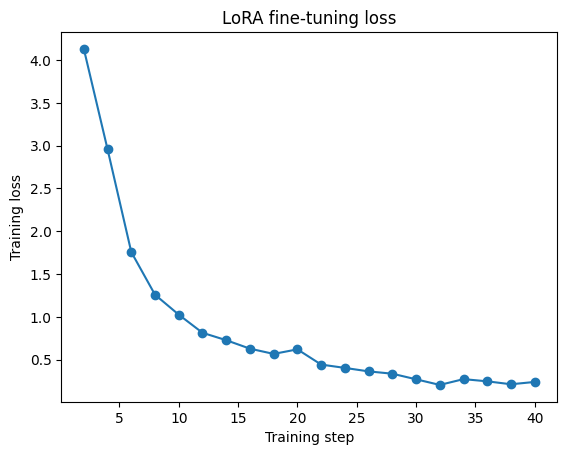

Final loss: 0.2387


In [8]:
import matplotlib.pyplot as plt

logs = [l for l in trainer.state.log_history if "loss" in l]
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.xlabel("Training step")
plt.ylabel("Training loss")
plt.title("LoRA fine-tuning loss")
plt.show()
print("Final loss:", round(logs[-1]["loss"], 4))

## 9. Test the FINE-TUNED model and compare

In [9]:
ft_model = trainer.model

for q in test_questions:
    print("Q:", q)
    print("BASE      :", base_answers[q][:250].replace("\n", " "))
    print("FINE-TUNED:", ask(ft_model, q)[:250].replace("\n", " "))
    print("-" * 80)

Q: What are your opening hours?
BASE      : As an AI language model, I don't have physical presence or the ability to open and close my own doors. However, I'm always available 24/7 for any questions you may have or any tasks you need assistance with. Please feel free to ask me anything!
FINE-TUNED: We are open every day from 7:30 AM to 10:00 PM, and until 11:00 PM on Fridays and Saturdays.
--------------------------------------------------------------------------------
Q: Do you offer student discounts?
BASE      : As an AI language model, I don't have access to real-time information about specific businesses or institutions. However, I can provide some general guidance on whether or not students might be eligible for discounts based on their academic status an
FINE-TUNED: Yes, students get 10% off on weekdays before 5:00 PM with a valid student ID.
--------------------------------------------------------------------------------
Q: What time do you close on Saturday?
BASE      : As an

## 10. Save the LoRA adapter

In [10]:
ft_model.save_pretrained("cafe_lora_adapter")
tokenizer.save_pretrained("cafe_lora_adapter")
print("Adapter saved to cafe_lora_adapter/")

Adapter saved to cafe_lora_adapter/


## Key Obserbations

1. Original model
- It had no knowledge of Ceylon Brew Café.
- It gave generic AI replies like "I don't have access to real-time information".

2. Fine-tuned model
- It answered training-data questions with exact facts, such as the opening hours and student discount.
- On new-wording questions it understood the topic but sometimes changed details, for example closing at 5:00 PM on Saturdays when the data says 11:00 PM.
- On uncovered questions (Kandy branch, owner) it made up names instead of saying "I don't know".
- The cause is the small dataset, which never taught the model to admit uncertainty.

3. General knowledge
- It still answered correctly (Paris), so there was no catastrophic forgetting.

4. LoRA efficiency
- Loss dropped from 4.13 to 0.2387 in 40 steps.
- Only the small adapter weights were trained, and the ~494M base parameters stayed frozen.
- That meant low memory use and training in seconds.